# UNMIX — ICA walkthrough

Step-by-step: mix three clean sources, **center**, **whiten by hand** (covariance + eigendecomposition), run **FastICA from scratch**, then evaluate against the originals while accounting for permutation, sign and scale ambiguity. Every cell calls the same modules the app uses (`whitening.py`, `ica.py`, `evaluation.py`).

In [1]:
import sys; sys.path.insert(0, '..')
import numpy as np, matplotlib.pyplot as plt
from IPython.display import Audio, display, Markdown
import audio_utils as au, evaluation as ev, visualization as viz
from whitening import center, covariance, pca_whiten, whiteness_error
from ica import fastica, run_ica, run_pca, excess_kurtosis
plt = viz.mpl_style(); import matplotlib; matplotlib.use('module://matplotlib_inline.backend_inline')
SR = 16_000

## 1 · Load sources (resample → mono → common length → standardise)

In [2]:
names = ['Speech (female)', 'Music', 'Rain']
files = ['speech_female.wav', 'music_neon_drift.wav', 'ambient_rain.wav']
S = au.standardize(au.load_sources([au.SOURCES_DIR / f for f in files], SR, duration_s=8))
print(S.shape, 'excess kurtosis:', excess_kurtosis(S).round(2))

(3, 128000) excess kurtosis: [3.84 0.87 9.49]


## 2 · Mix with our own matrix: X = A S

In [3]:
A = np.array([[1.00, 0.60, 0.45],
              [0.55, 1.00, 0.50],
              [0.40, 0.65, 1.00]])
X = au.mix(S, A)
print('cond(A) =', np.linalg.cond(A).round(2))
print('mixture kurtosis:', excess_kurtosis(X).round(2), ' <- closer to 0 (Gaussian): CLT at work')
display(Audio(X[0][:4*SR], rate=SR))

cond(A) = 5.46
mixture kurtosis: [1.58 0.64 3.58]  <- closer to 0 (Gaussian): CLT at work


## 3 · Center and whiten — by hand

$C = X_c X_c^T/(T-1) = E D E^T$, $K = D^{-1/2}E^T$, $Z = K X_c$ ⇒ $\mathrm{Cov}(Z)=I$.

In [4]:
Xc, mean = center(X)
C = covariance(Xc)
d, E = np.linalg.eigh(C)
print('Cov(X):\n', C.round(3))
print('eigenvalues:', d[::-1].round(3))
wr = pca_whiten(X)
print('Cov(Z):\n', np.cov(wr.Z).round(6))
print('max |Cov(Z)-I| =', whiteness_error(wr.Z))
KA = wr.K @ A
print('(K A)(K A)^T =\n', (KA @ KA.T).round(3))
print('≈ I: whitening turned the unknown mixing into a rotation (exact only if the finite-sample sources were exactly uncorrelated)')

Cov(X):
 [[1.556 1.374 1.238]
 [1.374 1.56  1.383]
 [1.238 1.383 1.595]]
eigenvalues: [4.235 0.338 0.139]
Cov(Z):
 [[ 1. -0. -0.]
 [-0.  1. -0.]
 [-0. -0.  1.]]
max |Cov(Z)-I| = 9.2148511043888e-15
(K A)(K A)^T =
 [[ 0.997  0.011 -0.008]
 [ 0.011  0.986  0.011]
 [-0.008  0.011  1.018]]
≈ I: whitening turned the unknown mixing into a rotation (exact only if the finite-sample sources were exactly uncorrelated)


## 4 · FastICA (log-cosh contrast, symmetric decorrelation)

In [5]:
W, n_iter, ok, hist = fastica(wr.Z, contrast='logcosh', algorithm='symmetric', seed=0)
Y = W @ wr.Z
print(f'converged={ok} after {n_iter} iterations')
print('W W^T =\n', (W @ W.T).round(10))
print('global (W K) A =\n', (W @ wr.K @ A).round(3))
plt.figure(figsize=(6,2.6)); plt.semilogy(np.maximum(hist,1e-16), 'o-', color=viz.CYAN); plt.title('convergence'); plt.xlabel('iteration'); plt.show()

converged=True after 5 iterations
W W^T =
 [[ 1.  0. -0.]
 [ 0.  1.  0.]
 [-0.  0.  1.]]
global (W K) A =
 [[ 0.006  1.    -0.013]
 [ 0.002 -0.006  1.   ]
 [ 1.    -0.002  0.011]]


<Figure size 600x260 with 1 Axes>

## 5 · Evaluate — Hungarian matching, sign/scale-invariant metrics

In [6]:
res = ev.evaluate(S, Y, X=X, W_total=W @ wr.K, A=A, names=names)
pca = ev.evaluate(S, run_pca(X), X=X, names=names)
import pandas as pd
df = pd.DataFrame(res['rows'])[['source','matched_component','sign','abs_corr','si_sdr','sir','input_si_sdr']]
df['pca_si_sdr'] = [r['si_sdr'] for r in pca['rows']]
display(df.round(3))
print({k: round(v, 4) for k, v in res['summary'].items()})

,source,matched_component,sign,abs_corr,si_sdr,sir,input_si_sdr,pca_si_sdr
0,Speech (female),3,1,1.0,39.315,39.315,2.347,0.835
1,Music,1,1,1.0,36.989,36.989,2.699,1.504
2,Rain,2,1,1.0,43.406,43.406,2.426,-3.590


{'mean_abs_corr': 0.9999, 'mean_si_sdr': 39.9035, 'mean_sir': 39.9035, 'mean_input_si_sdr': 2.4905, 'mean_si_sdr_improvement': 37.413, 'amari_index': 0.0066}


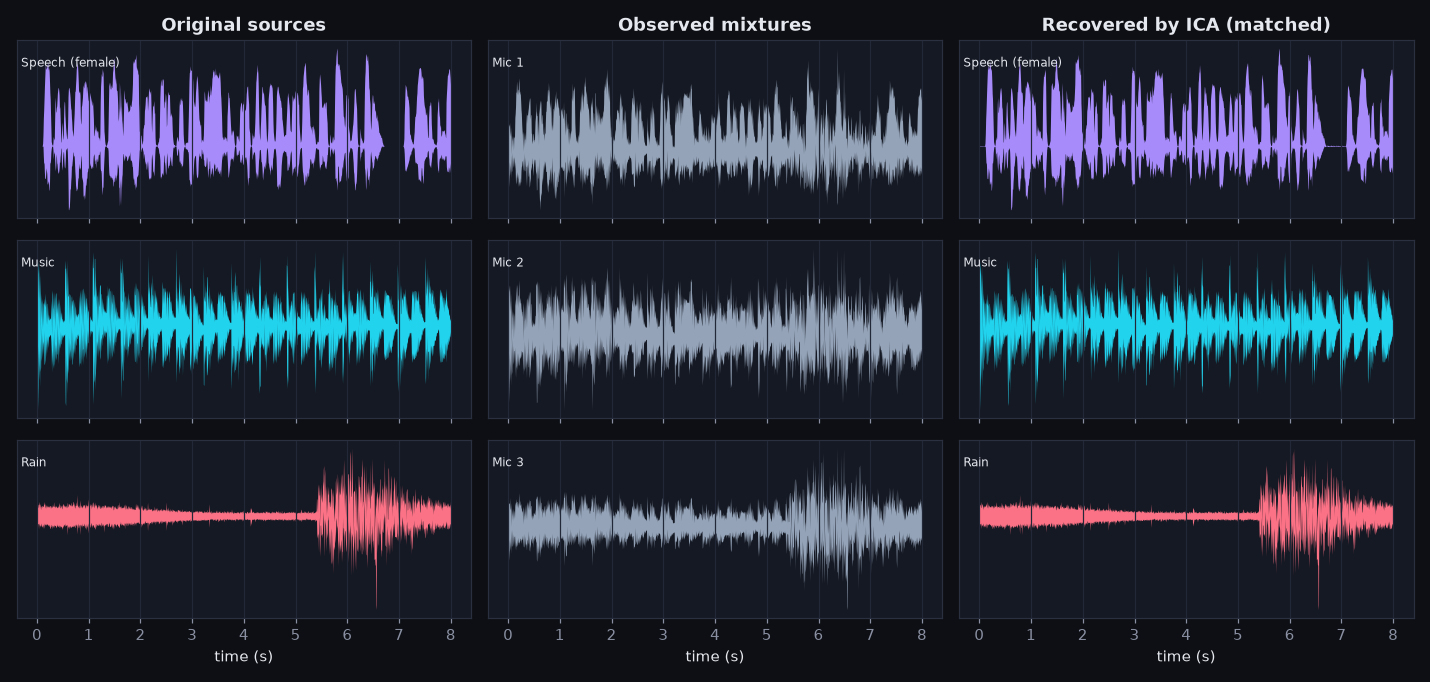

In [7]:
viz.mpl_reveal(S, X, res['aligned'], names, SR, 'reveal_nb.png')
from IPython.display import Image; display(Image('reveal_nb.png'))

### Listen: recovered sources (sign & scale aligned)

In [8]:
for n, y in zip(names, res['aligned']):
    display(Markdown(f'**{n}**')); display(Audio(y[:4*SR], rate=SR))

**Speech (female)**

**Music**

**Rain**

## 6 · PCA vs ICA under noise

In [9]:
rows = []
for snr in [None, 30, 20, 10, 0]:
    Xn = au.add_noise(X, snr, seed=0)
    r = run_ica(Xn)
    rows.append({'SNR': 'clean' if snr is None else snr,
                 'ICA SI-SDR': ev.evaluate(S, r.sources)['summary']['mean_si_sdr'],
                 'PCA SI-SDR': ev.evaluate(S, run_pca(Xn))['summary']['mean_si_sdr'],
                 'best mic': ev.evaluate(S, r.sources, X=Xn)['summary']['mean_input_si_sdr']})
pd.DataFrame(rows).round(2)

,SNR,ICA SI-SDR,PCA SI-SDR,best mic
0,clean,39.90,-0.42,2.49
1,30,22.65,-0.47,2.48
2,20,12.82,-0.91,2.37
3,10,3.41,-3.42,1.42
4,0,-5.26,-9.38,-3.29


## 7 · Why Gaussian sources break ICA

In [10]:
rng = np.random.default_rng(0)
G = au.standardize(np.vstack([S[0], rng.standard_normal(S.shape[1]), rng.standard_normal(S.shape[1])]))
r = run_ica(A @ G)
for row in ev.evaluate(G, r.sources, names=['speech','gauss A','gauss B'])['rows']:
    print(f"{row['source']:8s}  SI-SDR {row['si_sdr']:6.1f} dB")
print('-> the two Gaussian sources are not identifiable; the non-Gaussian speech still is.')

speech    SI-SDR   48.0 dB
gauss A   SI-SDR   -0.0 dB
gauss B   SI-SDR    0.1 dB
-> the two Gaussian sources are not identifiable; the non-Gaussian speech still is.


See `REPORT.md` for the full experiment suite (random matrices, SNR sweep, contrasts, number of sources, CLT, fingerprinting).